In [1]:
from typing import Tuple

import os
import numpy as np
import pandas as pd
import scanpy as sc
import anndata as ad
import seaborn as sns
import decoupler as dc

import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors

from tqdm.auto import tqdm
from anndata import AnnData

/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_csv from `anndata` is deprecated. Import anndata.io.read_csv instead.
  warnings.warn(msg, FutureWarning)
/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_excel from `anndata` is deprecated. Import anndata.io.read_excel instead.
  warnings.warn(msg, FutureWarning)
/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_hdf from `anndata` is deprecated. Import anndata.io.read_hdf instead.
  warnings.warn(msg, FutureWarning)
/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packages/anndata/utils.py:429: FutureWarning: Importing read_loom from `anndata` is deprecated. Import anndata.io.read_loom instead.
  warnings.warn(msg, FutureWarning)
/Users/soeren.becker/micromamba/envs/env_sc/lib/python3.12/site-packag

In [2]:
adata = sc.read_h5ad("/Users/soeren.becker/repos/HumanCytokineDict/data/use_case_datasets/06_lupus/lupus_norm_log1p.h5ad")

In [3]:
adata

AnnData object with n_obs × n_vars = 1263676 × 30933
    obs: 'library_uuid', 'cell_type_ontology_term_id', 'author_cell_type', 'cell_state', 'sample_uuid', 'development_stage_ontology_term_id', 'disease_state', 'suspension_uuid', 'donor_id', 'self_reported_ethnicity_ontology_term_id', 'disease_ontology_term_id', 'sex_ontology_term_id', 'Processing_Cohort', 'ct_cov', 'ind_cov', 'cell_type', 'disease', 'sex', 'self_reported_ethnicity', 'development_stage'
    var: 'mean_expr_raw', 'frac_expr_cells', 'mean_expr_log1p'
    uns: 'cell_type_colors', 'log1p'
    obsm: 'X_umap'

In [4]:
with pd.option_context("display.max_columns", 100):
    display(adata.obs.head())

,library_uuid,cell_type_ontology_term_id,author_cell_type,cell_state,sample_uuid,development_stage_ontology_term_id,disease_state,suspension_uuid,donor_id,self_reported_ethnicity_ontology_term_id,disease_ontology_term_id,sex_ontology_term_id,Processing_Cohort,ct_cov,ind_cov,cell_type,disease,sex,self_reported_ethnicity,development_stage
cellId,,,,,,,,,,,,,,,,,,,,
CAAGGCCAGTATCGAA-1-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-1-0-0-0-0-0,3332f018-936e-4c4c-9105-99d9503db5a3,CL:0000624,T4,na,0a1148dc-356f-4dc4-9c32-bf0823257d93,HsapDv:0000122,na,cc418a0a-d636-4eca-a44c-db537d30b486,HC-546,HANCESTRO:0008,PATO:0000461,PATO:0000383,4.0,T4_naive,HC-546,"CD4-positive, alpha-beta T cell",normal,female,Asian,28-year-old human stage
CTAACTTCAATGAATG-1-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-1-0-0-0-0-0,70a004b7-4a17-4702-8910-4557aa0c4279,CL:0000860,cM,na,577bce84-8d37-4851-9fb4-53f9467699ba,HsapDv:0000139,managed,3e67947f-bd15-4d41-910a-89488e72c50a,1132,HANCESTRO:0005,MONDO:0007915,PATO:0000383,4.0,NaN,1132_1132,classical monocyte,systemic lupus erythematosus,female,European,45-year-old human stage
AAGTCTGGTCTACCTC-1-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0,152e2bfd-e9ea-4d70-a999-6f37fb3fb96c,CL:0000860,cM,na,0f3a21f5-e7b9-4139-93fb-5407dbfde4fc,HsapDv:0000128,flare,9741923d-1aa6-4701-8382-34cc020e6027,FLARE006,HANCESTRO:0005,MONDO:0007915,PATO:0000383,3.0,NaN,FLARE006,classical monocyte,systemic lupus erythematosus,female,European,34-year-old human stage
GGCTCGATCGTTGACA-1-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-1-0-0-0-0-0-0-0-0-0-0,c2641f62-eb23-4dad-9c22-b52e72b79df2,CL:0000236,B,na,5e0ed28c-a75a-4ecd-a0c7-49e71264690b,HsapDv:0000165,managed,9a1dccc2-dd02-40d1-a50a-81ac0c094edc,1110,HANCESTRO:0005,MONDO:0007915,PATO:0000383,4.0,B_naive,1110_1110,B cell,systemic lupus erythematosus,female,European,71-year-old human stage
ACACCGGCACACAGAG-1-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-1-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0-0,222b358b-71e7-4b0f-9f9b-47b4c67aaa27,CL:0000624,T4,na,982d60b4-5677-4e2d-8b58-79503863710d,HsapDv:0000122,managed,8f3811f4-79dd-4522-bc30-157c28507dbd,1479,HANCESTRO:0008,MONDO:0007915,PATO:0000383,2.0,NaN,1479_1479,"CD4-positive, alpha-beta T cell",systemic lupus erythematosus,female,Asian,28-year-old human stage


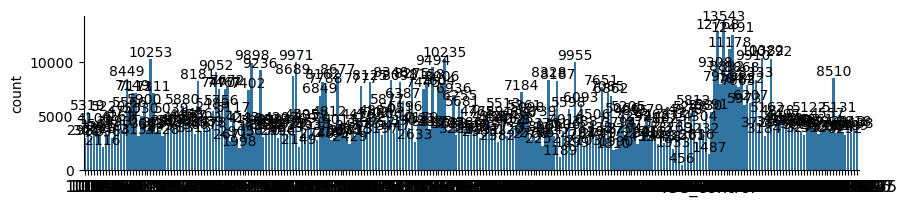

In [5]:
fig, ax = plt.subplots(1,1,figsize=(10, 2))
ax=sns.barplot(adata.obs.donor_id.value_counts())
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d')
sns.despine()
plt.xticks(rotation=0, fontsize=12)
plt.xlabel("")
#plt.ylabel("")
plt.show()

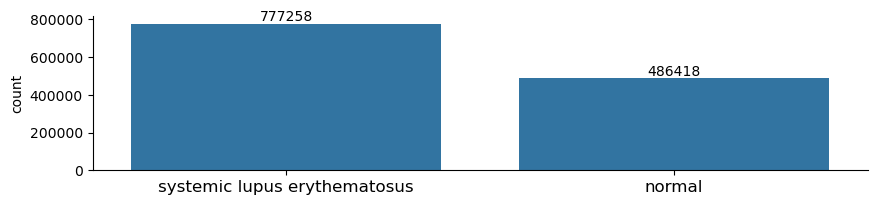

In [6]:
order = adata.obs.disease.value_counts().index.values
fig, ax = plt.subplots(1,1,figsize=(10, 2))
ax=sns.barplot(adata.obs.disease.value_counts(), order=order)
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d')
sns.despine()
plt.xticks(rotation=0, fontsize=12)
plt.xlabel("")
#plt.ylabel("")
plt.show()

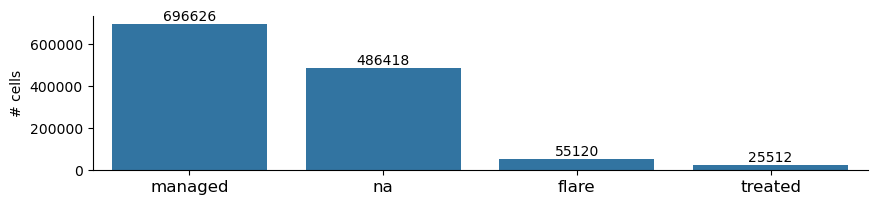

In [7]:
order = adata.obs.disease_state.value_counts().index.values
fig, ax = plt.subplots(1,1,figsize=(10, 2))
ax=sns.barplot(adata.obs.disease_state.value_counts(), order=order)
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d')
sns.despine()
plt.xticks(rotation=0, fontsize=12)
plt.xlabel("")
plt.ylabel("# cells")
plt.show()

In [8]:
adata.obs.donor_id.nunique()

261

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_49233/4113403344.py:3: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ax=sns.barplot(adata.obs.groupby("disease_state").donor_id.nunique(), order=order)


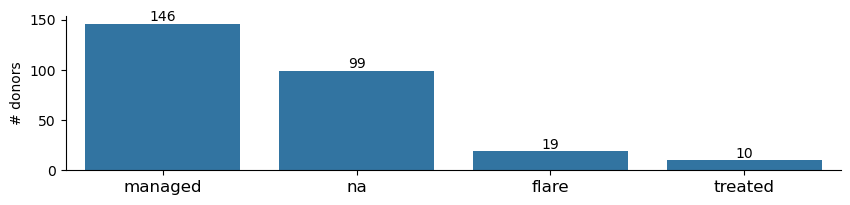

In [9]:
order = adata.obs.disease_state.value_counts().index.values
fig, ax = plt.subplots(1,1,figsize=(10, 2))
ax=sns.barplot(adata.obs.groupby("disease_state").donor_id.nunique(), order=order)
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d')
sns.despine()
plt.xticks(rotation=0, fontsize=12)
plt.xlabel("")
plt.ylabel("# donors")
plt.show()

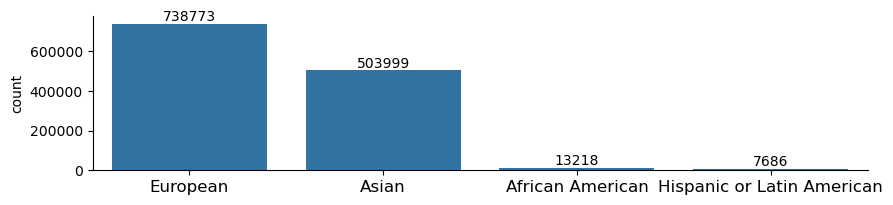

In [10]:
order = adata.obs.self_reported_ethnicity.value_counts().index.values
fig, ax = plt.subplots(1,1,figsize=(10, 2))
ax=sns.barplot(adata.obs.self_reported_ethnicity.value_counts(), order=order)
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d')
sns.despine()
plt.xticks(rotation=0, fontsize=12)
plt.xlabel("")
#plt.ylabel("")
plt.show()

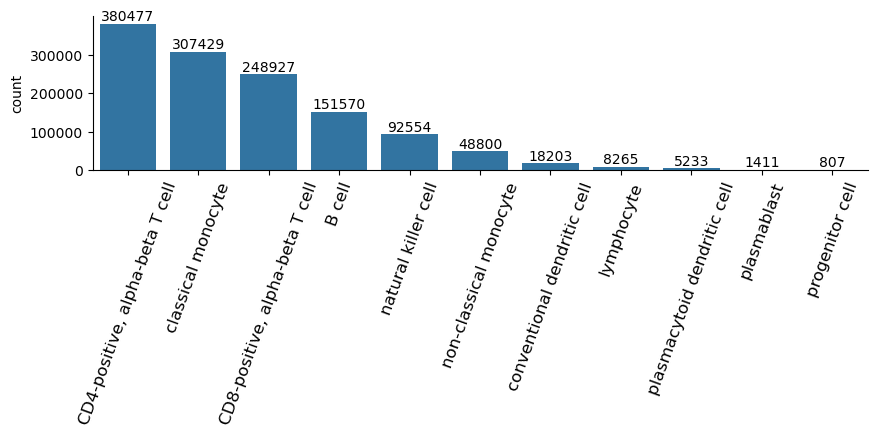

In [11]:
order = adata.obs.cell_type.value_counts().index.values
fig, ax = plt.subplots(1,1,figsize=(10, 2))
ax=sns.barplot(adata.obs.cell_type.value_counts(), order=order)
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d')
sns.despine()
plt.xticks(rotation=70, fontsize=12)
plt.xlabel("")
#plt.ylabel("")
plt.show()

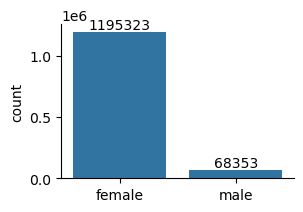

In [12]:
fig, ax = plt.subplots(1,1,figsize=(3, 2))
ax=sns.barplot(adata.obs.sex.value_counts())
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d')
sns.despine()
plt.xlabel("")
# plt.ylabel("")
plt.show()

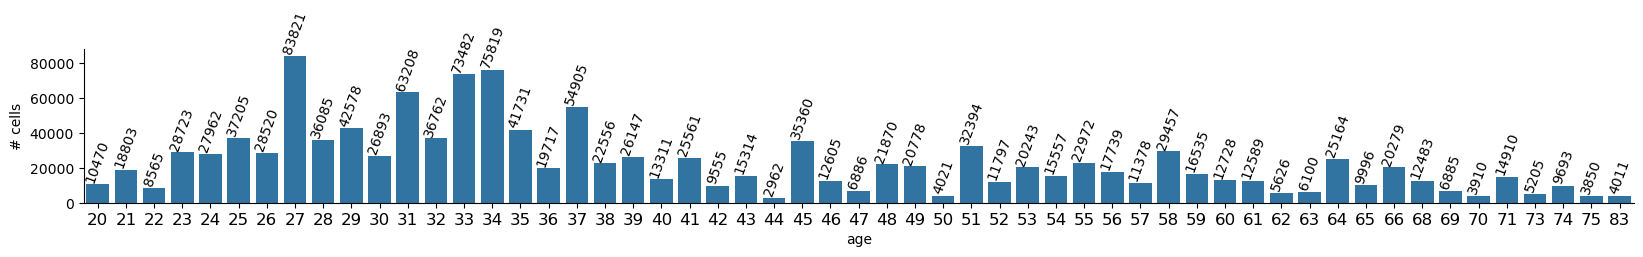

In [13]:
adata.obs.loc[:, "age"] = adata.obs.development_stage.str.split("-").str.get(0).astype(int)
fig, ax = plt.subplots(1,1,figsize=(20, 2))
ax=sns.barplot(adata.obs.age.value_counts())
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d', rotation=70)
sns.despine()
plt.xticks(rotation=0, fontsize=12)
#plt.xlabel("")
plt.ylabel("# cells")
plt.show()

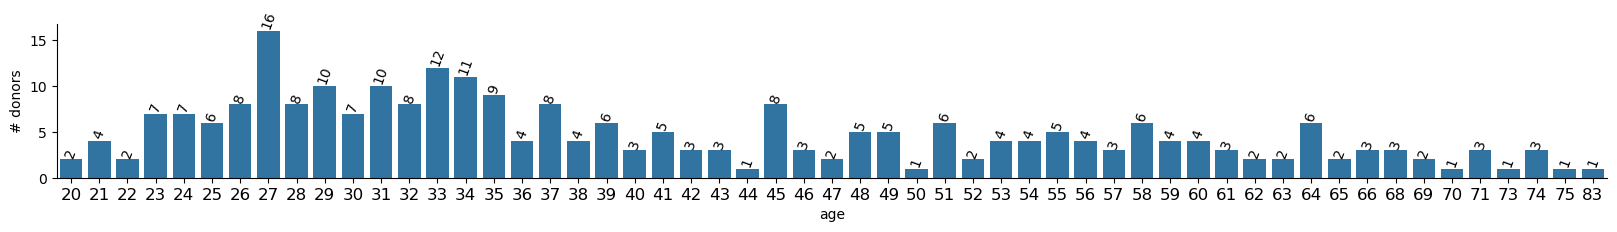

In [14]:
adata.obs.loc[:, "age"] = adata.obs.development_stage.str.split("-").str.get(0).astype(int)
fig, ax = plt.subplots(1,1,figsize=(20, 2))
ax=sns.barplot(adata.obs.groupby("age").donor_id.nunique())
ax.bar_label(ax.containers[0], fontsize=10, fmt = '%d', rotation=70)
sns.despine()
plt.xticks(rotation=0, fontsize=12)
#plt.xlabel("")
plt.ylabel("# donors")
plt.show()

In [15]:
from weasyprint import HTML

def table_to_pdf(df: pd.DataFrame, path: str):

    df.index.name = None
    df.columns.name = None
    
    # Convert to HTML (without border)
    html_table = df.to_html(classes="styled-table", border=0)
    
    # CSS for your desired style
    custom_css = """
    <style>
    table.styled-table {
        border-collapse: collapse;
        width: 50%;
        table-layout: fixed; /* ensures equal column widths */
        font-family: "DejaVu Sans", Arial, sans-serif;
        font-size: 6pt;
    }
    .styled-table th, .styled-table td {
        border: 1px solid #ddd;
        padding: 6px 8px;
        text-align: center; /* right-align numbers */
    }
    .styled-table th {
        background-color: #f2f2f2;
        text-align: center;
    }
    .styled-table tr:nth-child(even) {
        background-color: #f9f9f9;
    }
    .styled-table tr:nth-child(odd) {
        background-color: #ffffff;
    }
    .styled-table thead th {
        font-weight: bold;
    }
    </style>
    """
    
    # Combine HTML + CSS
    html_doc = f"""
    <html>
    <head>
    <meta charset="utf-8">
    {custom_css}
    </head>
    <body>
    {html_table}
    </body>
    </html>
    """
    
    # Write to PDF
    HTML(string=html_doc).write_pdf(path)

In [16]:
obs = adata.obs.copy()
obs.loc[:, "disease_state"] = obs.loc[:, "disease_state"].apply(lambda x: "healthy" if x == "na" else x)
obs = obs.loc[obs.disease_state.isin(["flare", "healthy", "treated"])]
obs["disease_state"] = obs["disease_state"].cat.remove_unused_categories()
counts = obs.groupby("self_reported_ethnicity").disease_state.value_counts().to_frame().reset_index()
ethnicity_order = ['Asian', 'African American', 'European', 'Hispanic or Latin American']
disease_state_order = ["healthy", "flare", "treated"]

df_pivot = counts.pivot(
    index="self_reported_ethnicity",
    columns="disease_state",
    values="count"
).loc[ethnicity_order, disease_state_order]

display(df_pivot)
table_to_pdf(df_pivot, "./table_num_cells.pdf")

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_49233/401026034.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['healthy', 'managed', 'flare', 'managed', 'managed', ..., 'healthy', 'healthy', 'healthy', 'managed', 'managed']
Length: 1263676
Categories (4, object): ['flare', 'managed', 'healthy', 'treated']' has dtype incompatible with category, please explicitly cast to a compatible dtype first.
  obs.loc[:, "disease_state"] = obs.loc[:, "disease_state"].apply(lambda x: "healthy" if x == "na" else x)
/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_49233/401026034.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = obs.groupby("self_reported_ethnicity").disease_state.value_counts().to_frame()

disease_state,healthy,flare,treated
self_reported_ethnicity,,,
Asian,88920,23025,14472
African American,0,9729,3489
European,394551,19882,5296
Hispanic or Latin American,2947,2484,2255


In [17]:
obs = adata.obs.copy()
obs.loc[:, "disease_state"] = obs.loc[:, "disease_state"].apply(lambda x: "healthy" if x == "na" else x)
obs = obs.loc[obs.disease_state.isin(["flare", "healthy", "treated"])]
obs["disease_state"] = obs["disease_state"].cat.remove_unused_categories()
counts = obs.groupby(["self_reported_ethnicity", "disease_state"]).donor_id.nunique().to_frame().reset_index()
ethnicity_order = ['Asian', 'African American', 'European', 'Hispanic or Latin American']
disease_state_order = ["healthy", "flare", "treated"]
df_pivot = counts.pivot(
    index="self_reported_ethnicity",
    columns="disease_state",
    values="donor_id"
).loc[ethnicity_order, disease_state_order]

display(df_pivot)
table_to_pdf(df_pivot, "./table_num_donors.pdf")

/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_49233/868373155.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '['healthy', 'managed', 'flare', 'managed', 'managed', ..., 'healthy', 'healthy', 'healthy', 'managed', 'managed']
Length: 1263676
Categories (4, object): ['flare', 'managed', 'healthy', 'treated']' has dtype incompatible with category, please explicitly cast to a compatible dtype first.
  obs.loc[:, "disease_state"] = obs.loc[:, "disease_state"].apply(lambda x: "healthy" if x == "na" else x)
/var/folders/sh/v5nqfs0d4fg8c9jd550tt09h0000gn/T/ipykernel_49233/868373155.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = obs.groupby(["self_reported_ethnicity", "disease_state"]).donor_id.nunique().t

disease_state,healthy,flare,treated
self_reported_ethnicity,,,
Asian,24,9,6
African American,0,3,1
European,74,6,2
Hispanic or Latin American,1,1,1
